In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style= "darkgrid", color_codes = True)
from tensorflow.keras.applications import ResNet50V2 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Dense, Flatten, Dropout, Input, GlobalAveragePooling2D
from keras.regularizers import l2
import warnings
warnings.filterwarnings('ignore')
tf.config.optimizer.set_jit(False)
# Vérifier si GPU est disponible
if tf.config.list_physical_devices('GPU'):
    # Permettre la croissance de la mémoire GPU
    for gpu in tf.config.experimental.list_physical_devices('GPU'):
        tf.config.experimental.set_memory_growth(gpu, True)
print("GPU disponible:", tf.config.list_physical_devices('GPU'))

2025-04-08 09:48:29.916884: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-08 09:48:30.075385: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744098510.122976   13483 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744098510.133689   13483 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1744098510.273925   13483 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Define image size and other parameters
img_width, img_height = 128, 128
batchsize = 32
epochs = 6
num_of_class = 2
import tensorflow as tf
import os
import random

def create_balanced_three_class_dataset(directory, batch_size, img_size):
    normal_path = os.path.join(directory, 'NORMAL')
    pneumonia_path = os.path.join(directory, 'PNEUMONIA')

    # Récupération des fichiers et attribution des labels one-hot
    normal_files = [(os.path.join(normal_path, f), [1,0,0]) 
                    for f in os.listdir(normal_path) 
                    if f.endswith(('.jpeg', '.jpg', '.png'))]

    viral_files = [(os.path.join(pneumonia_path, f), [0,1,0]) 
                   for f in os.listdir(pneumonia_path) 
                   if 'virus' in f.lower() and f.endswith(('.jpeg', '.jpg', '.png'))]

    bacterial_files = [(os.path.join(pneumonia_path, f), [0,0,1]) 
                       for f in os.listdir(pneumonia_path) 
                       if 'bacteria' in f.lower() and f.endswith(('.jpeg', '.jpg', '.png'))]

    # Calcul du plus petit nombre d'images disponibles
    min_count = min(len(normal_files), len(viral_files), len(bacterial_files))

    # Équilibrer les classes
    random.shuffle(normal_files)
    random.shuffle(viral_files)
    random.shuffle(bacterial_files)

    normal_files = normal_files[:min_count]
    viral_files = viral_files[:min_count]
    bacterial_files = bacterial_files[:min_count]

    # Fusionner toutes les données
    all_data = normal_files + viral_files + bacterial_files
    random.shuffle(all_data)

    print(f"[{directory}] Normal: {len(normal_files)}, Viral: {len(viral_files)}, Bacterial: {len(bacterial_files)}")


    file_paths, labels = zip(*all_data)

    # Création du dataset
    def load_and_preprocess_image(file_path, label):
        img = tf.io.read_file(file_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, img_size)
        img = img / 255.0
        return img, label

    dataset = tf.data.Dataset.from_tensor_slices((list(file_paths), list(labels)))
    dataset = dataset.map(load_and_preprocess_image)
    dataset = dataset.shuffle(buffer_size=len(all_data))
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return dataset


# Charger les datasets
img_size = (img_width, img_height)
train = create_balanced_three_class_dataset('chest_xray/train', batchsize, img_size)
validation = create_balanced_three_class_dataset('chest_xray/val', batchsize, img_size)
test = create_balanced_three_class_dataset('chest_xray/test', batchsize, img_size)

# Vérifier la forme des données
for images, labels in train.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Sample labels:", labels[0])  # Devrait montrer un vecteur one-hot de taille 3

[chest_xray/train] Normal: 1341, Viral: 1341, Bacterial: 1341
[chest_xray/val] Normal: 8, Viral: 8, Bacterial: 8
[chest_xray/test] Normal: 148, Viral: 148, Bacterial: 148


I0000 00:00:1744098514.008183   13483 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA RTX 1000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Images shape: (32, 128, 128, 3)
Labels shape: (32, 3)
Sample labels: tf.Tensor([0 0 1], shape=(3,), dtype=int32)


2025-04-08 09:48:36.535152: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Format des labels: [0 1 0]
Label 0: [0.0, 1.0, 0.0]
Label 1: [1.0, 0.0, 0.0]
Label 2: [0.0, 1.0, 0.0]
Label 3: [0.0, 1.0, 0.0]


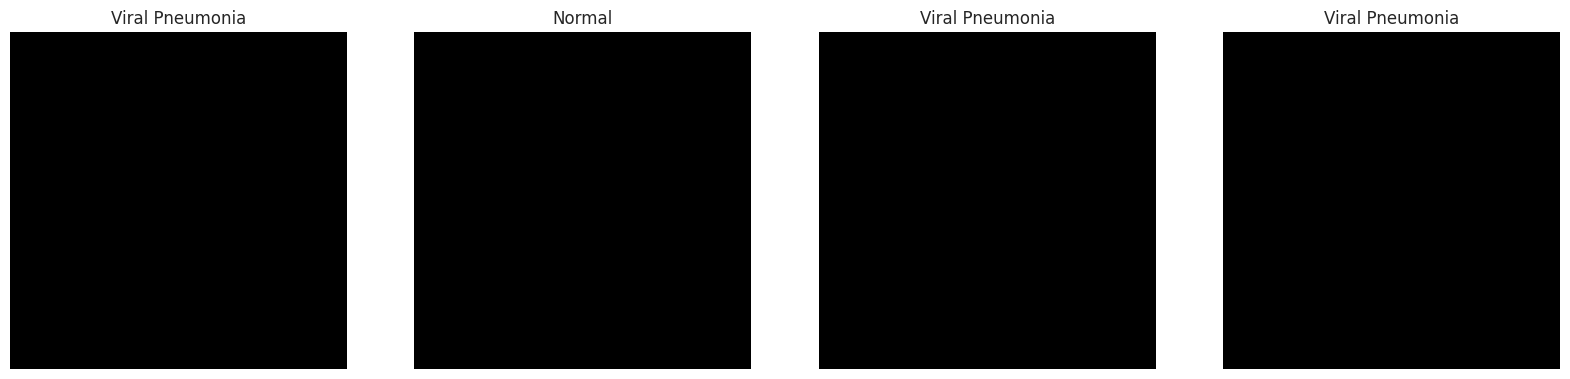

In [3]:
data_iterator = train.as_numpy_iterator()
batch = data_iterator.next()

# Afficher un exemple de label pour debug
print("Format des labels:", batch[1][0])

# Créer un dictionnaire pour convertir les labels one-hot en texte
label_dict = {
    '[1.0, 0.0, 0.0]': "Normal",
    '[0.0, 1.0, 0.0]': "Viral Pneumonia",
    '[0.0, 0.0, 1.0]': "Bacterial Pneumonia"
}

fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    # Convertir le label en string avec le bon format
    label_str = str([float(x) for x in batch[1][idx].tolist()])
    print(f"Label {idx}:", label_str)  # Debug
    label = label_dict.get(label_str, "Unknown")
    ax[idx].title.set_text(label)
    ax[idx].axis('off')

plt.show()

In [4]:
from tensorflow.keras.utils import to_categorical
# Définir une taille fixe pour toutes les images
IMG_SIZE = (128, 128)  # Taille standard pour VGG16

# Extracting Features and Labels
x_train = []
y_train = []
x_val = []
y_val = []
x_test = []
y_test = []

# Fonction pour traiter un batch
def process_batch(batch):
    features, labels = batch
    features = tf.image.resize(features, IMG_SIZE)
    return features.numpy(), labels.numpy()

# Traiter les données d'entraînement
for batch in train:
    features, labels = process_batch(batch)
    x_train.extend(features)
    y_train.extend(labels)

# Traiter les données de test
for batch in test:
    features, labels = process_batch(batch)
    x_test.extend(features)
    y_test.extend(labels)

# Traiter les données de validation
for batch in validation:
    features, labels = process_batch(batch)
    x_val.extend(features)
    y_val.extend(labels)

# Convertir en arrays numpy
x_train = np.array(x_train, dtype=np.float32)
x_val = np.array(x_val, dtype=np.float32)
x_test = np.array(x_test, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)
y_val = np.array(y_val, dtype=np.float32)
y_test = np.array(y_test, dtype=np.float32)

# Normaliser les images
x_train = tf.image.resize(x_train, IMG_SIZE)
x_val = tf.image.resize(x_val, IMG_SIZE)
x_test = tf.image.resize(x_test, IMG_SIZE)


# Vérifier les shapes
print("Shape de x_train:", x_train.shape)
print("Shape de y_train:", y_train.shape)
print("Shape de x_val:", x_val.shape)
print("Shape de y_val:", y_val.shape)
print("Shape de x_test:", x_test.shape)
print("Shape de y_test:", y_test.shape)

# Vérifier les valeurs uniques dans les labels
print("\nValeurs uniques dans y_train:", np.unique(y_train, axis=0))

2025-04-08 09:48:42.458375: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2025-04-08 09:48:42.874120: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Shape de x_train: (4023, 128, 128, 3)
Shape de y_train: (4023, 3)
Shape de x_val: (24, 128, 128, 3)
Shape de y_val: (24, 3)
Shape de x_test: (444, 128, 128, 3)
Shape de y_test: (444, 3)

Valeurs uniques dans y_train: [[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]]


In [5]:
# check the shapes of 'x_train' and 'y_train':
print("Shape of 'x_train':", x_train.shape)
print("Shape of 'y_train':", y_train.shape)
print("Shape of 'x_val':", x_val.shape)
print("Shape of 'y_val':", y_val.shape)
print("Shape of 'x_test':", x_test.shape)
print("Shape of 'y_test':", y_test.shape)

Shape of 'x_train': (4023, 128, 128, 3)
Shape of 'y_train': (4023, 3)
Shape of 'x_val': (24, 128, 128, 3)
Shape of 'y_val': (24, 3)
Shape of 'x_test': (444, 128, 128, 3)
Shape of 'y_test': (444, 3)


In [6]:
def create_model():
    base_model = ResNet50V2 (weights='imagenet', 
                      include_top=False, 
                      input_shape=(128, 128, 3))

    base_model.trainable = False
    
    model = Sequential([
        base_model,
        Flatten(),
        Dropout(0.4),
        Dense(256, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        Dense(3, activation='softmax')
    ])
    
    # Learning rate plus faible pour un meilleur apprentissage
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)
    
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy', 'Precision', 'Recall']
    )

    model.summary()
    
    return model

Fold 1/5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,986,947 (122.02 MB)

 Trainable params: 31,941,507 (121.85 MB)

...

Epoch 1/15


I0000 00:00:1744098538.955308   13640 service.cc:152] XLA service 0x7f6f4c002b10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1744098538.955345   13640 service.cc:160]   StreamExecutor device (0): NVIDIA RTX 1000 Ada Generation Laptop GPU, Compute Capability 8.9
2025-04-08 09:48:59.382806: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1744098541.559412   13640 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1744098560.527252   13640 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


100/101 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - Precision: 0.6224 - Recall: 0.5694 - accuracy: 0.6085 - loss: 7.0260

2025-04-08 09:49:34.281833: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_15555', 4 bytes spill stores, 4 bytes spill loads

2025-04-08 09:49:37.229626: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.15GiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


101/101 ━━━━━━━━━━━━━━━━━━━━ 70s 360ms/step - Precision: 0.6237 - Recall: 0.5709 - accuracy: 0.6099 - loss: 7.0131 - val_Precision: 0.7326 - val_Recall: 0.6944 - val_accuracy: 0.7155 - val_loss: 5.6572 - learning_rate: 1.0000e-04
Epoch 2/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - Precision: 0.8273 - Recall: 0.7996 - accuracy: 0.8132 - loss: 5.2872 - val_Precision: 0.7911 - val_Recall: 0.7764 - val_accuracy: 0.7826 - val_loss: 4.9638 - learning_rate: 1.0000e-04
Epoch 3/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 107ms/step - Precision: 0.8804 - Recall: 0.8653 - accuracy: 0.8730 - loss: 4.6858 - val_Precision: 0.7778 - val_Recall: 0.7565 - val_accuracy: 0.7677 - val_loss: 4.5640 - learning_rate: 1.0000e-04
Epoch 4/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 21s 106ms/step - Precision: 0.9208 - Recall: 0.9156 - accuracy: 0.9190 - loss: 4.1941 - val_Precision: 0.7790 - val_Recall: 0.7665 - val_accuracy: 0.7714 - val_loss: 4.4500 - learning_rate: 1.0000e-04
Epoch 5/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 108

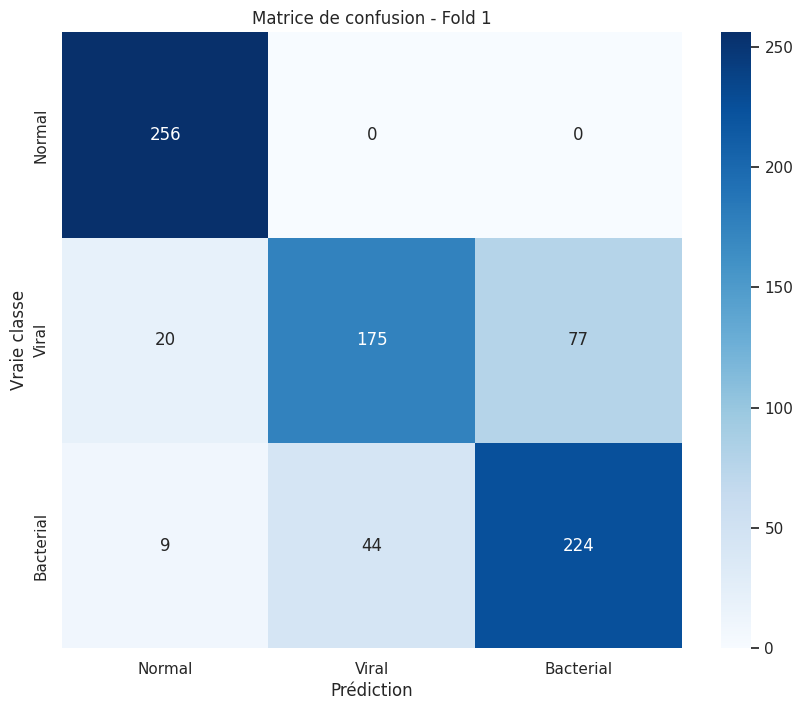


Métriques détaillées pour le Fold 1:

Classe: Normal
True Positives (TP): 256
True Negatives (TN): 520
False Positives (FP): 29
False Negatives (FN): 0
Precision: 0.8982
Recall: 1.0000

Classe: Viral
True Positives (TP): 175
True Negatives (TN): 489
False Positives (FP): 44
False Negatives (FN): 97
Precision: 0.7991
Recall: 0.6434

Classe: Bacterial
True Positives (TP): 224
True Negatives (TN): 451
False Positives (FP): 77
False Negatives (FN): 53
Precision: 0.7442
Recall: 0.8087

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.90      1.00      0.95       256
       Viral       0.80      0.64      0.71       272
   Bacterial       0.74      0.81      0.78       277

    accuracy                           0.81       805
   macro avg       0.81      0.82      0.81       805
weighted avg       0.81      0.81      0.81       805



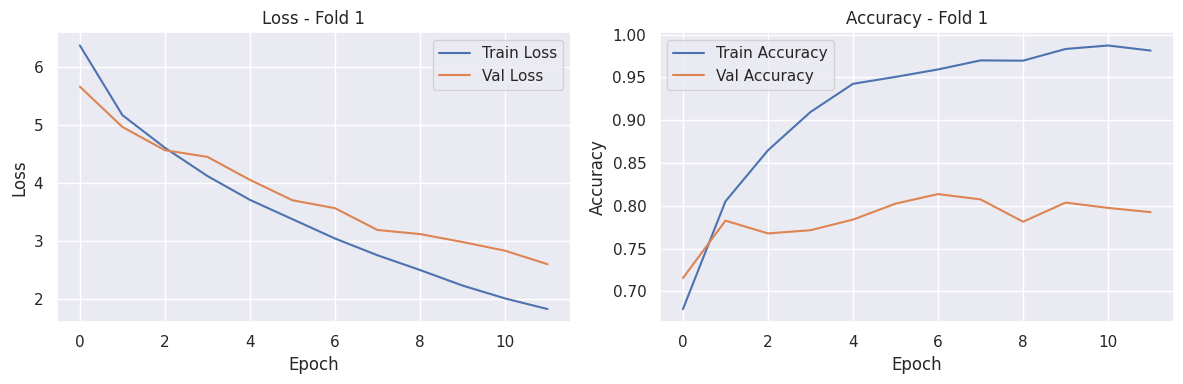

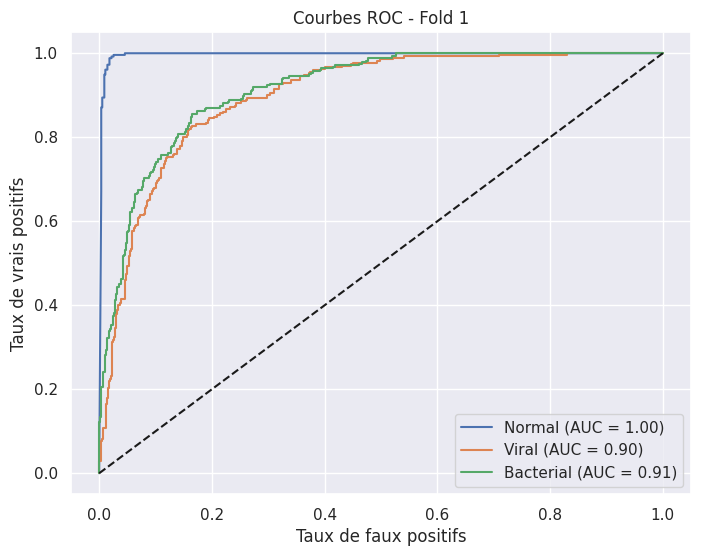

Fold 2/5


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,986,947 (122.02 MB)

 Trainable params: 31,941,507 (121.85 MB)

 Non-trainable params: 45,440 (177.50 KB)

Epoch 1/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 51s 265ms/step - Precision: 0.6087 - Recall: 0.5564 - accuracy: 0.5955 - loss: 7.1199 - val_Precision: 0.7539 - val_Recall: 0.7155 - val_accuracy: 0.7329 - val_loss: 5.6295 - learning_rate: 1.0000e-04
Epoch 2/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - Precision: 0.8146 - Recall: 0.7797 - accuracy: 0.8039 - loss: 5.3644 - val_Precision: 0.7718 - val_Recall: 0.7602 - val_accuracy: 0.7627 - val_loss: 5.0449 - learning_rate: 1.0000e-04
Epoch 3/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - Precision: 0.8619 - Recall: 0.8481 - accuracy: 0.8578 - loss: 4.7651 - val_Precision: 0.7614 - val_Recall: 0.7491 - val_accuracy: 0.7578 - val_loss: 4.7154 - learning_rate: 1.0000e-04
Epoch 4/15
101/101 ━━━━━━━━━━━━━━━━━━━━ 11s 109ms/step - Precision: 0.9146 - Recall: 0.9044 - accuracy: 0.9102 - loss: 4.2530 - val_Precision: 0.7679 - val_Recall: 0.7602 - val_accuracy: 0.7665 - val_loss: 4.3379 - learning_rate: 1.0000e-04
Epoch 5/15
101/101 ━━━━━━━━━━━━━━━━━

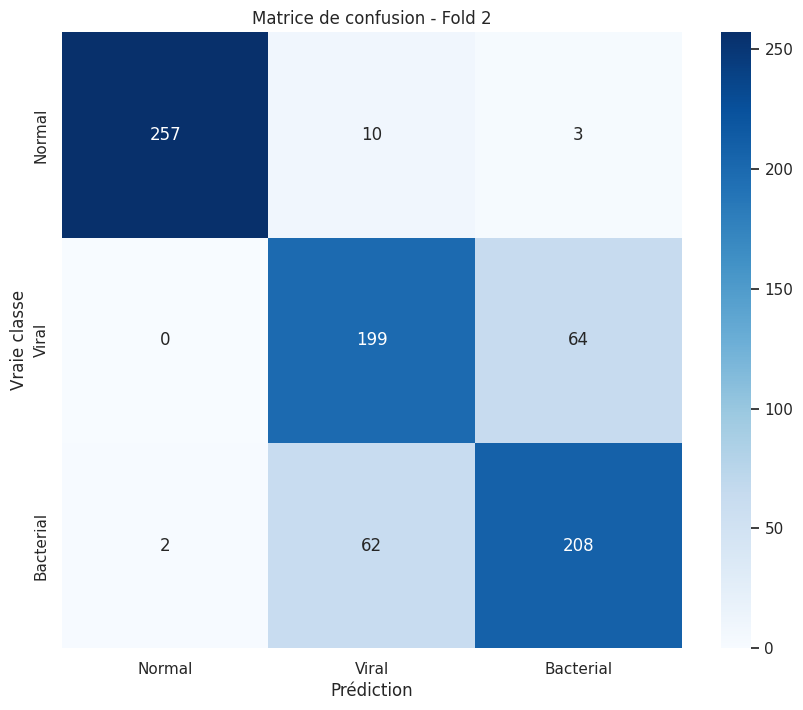


Métriques détaillées pour le Fold 2:

Classe: Normal
True Positives (TP): 257
True Negatives (TN): 533
False Positives (FP): 2
False Negatives (FN): 13
Precision: 0.9923
Recall: 0.9519

Classe: Viral
True Positives (TP): 199
True Negatives (TN): 470
False Positives (FP): 72
False Negatives (FN): 64
Precision: 0.7343
Recall: 0.7567

Classe: Bacterial
True Positives (TP): 208
True Negatives (TN): 466
False Positives (FP): 67
False Negatives (FN): 64
Precision: 0.7564
Recall: 0.7647

Rapport de classification détaillé:
              precision    recall  f1-score   support

      Normal       0.99      0.95      0.97       270
       Viral       0.73      0.76      0.75       263
   Bacterial       0.76      0.76      0.76       272

    accuracy                           0.82       805
   macro avg       0.83      0.82      0.83       805
weighted avg       0.83      0.82      0.83       805



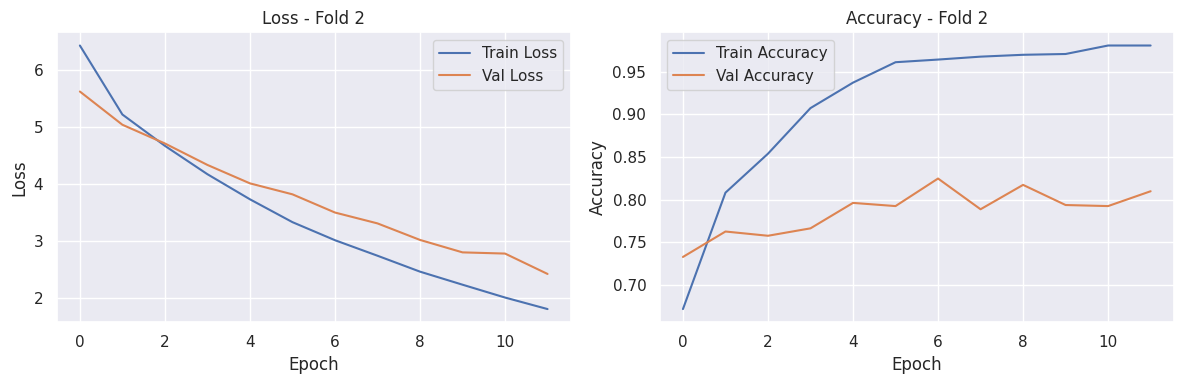

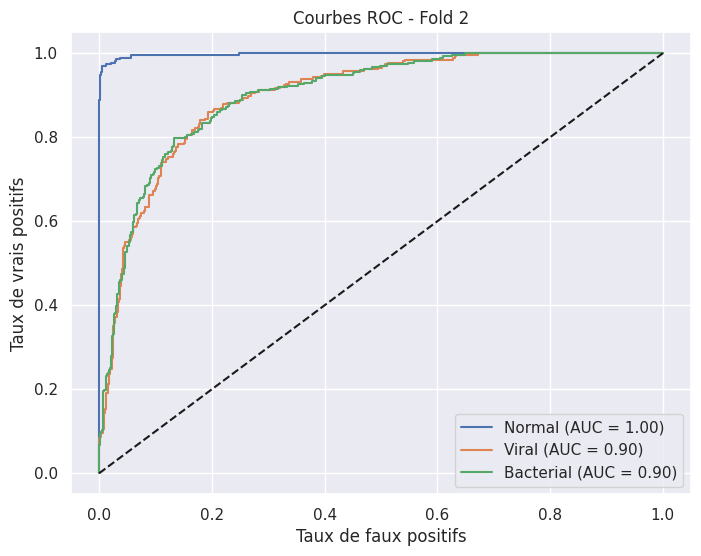

Fold 3/5


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50v2 (Functional)         │ (None, 4, 4, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,986,947 (122.02 MB)

 Trainable params: 31,941,507 (121.85 MB)

 Non-trainable params: 45,440 (177.50 KB)

Epoch 1/15


2025-04-08 09:55:46.435630: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:501] Allocator (GPU_0_bfc) ran out of memory trying to allocate 4.00MiB (rounded to 4194304)requested by op 
2025-04-08 09:55:46.435811: I external/local_xla/xla/tsl/framework/bfc_allocator.cc:1058] BFCAllocator dump for GPU_0_bfc
2025-04-08 09:55:46.435820: I external/local_xla/xla/tsl/framework/bfc_allocator.cc:1065] Bin (256): 	Total Chunks: 9196, Chunks in use: 9196. 2.25MiB allocated for chunks. 2.25MiB in use in bin. 79.9KiB client-requested in use in bin.
2025-04-08 09:55:46.435823: I external/local_xla/xla/tsl/framework/bfc_allocator.cc:1065] Bin (512): 	Total Chunks: 201, Chunks in use: 201. 100.8KiB allocated for chunks. 100.8KiB in use in bin. 100.4KiB client-requested in use in bin.
2025-04-08 09:55:46.435825: I external/local_xla/xla/tsl/framework/bfc_allocator.cc:1065] Bin (1024): 	Total Chunks: 412, Chunks in use: 412. 419.2KiB allocated for chunks. 419.2KiB in use in bin. 415.5KiB client

RuntimeError: pybind11::error_already_set: MISMATCH of original and normalized active exception types: ORIGINAL ResourceExhaustedError REPLACED BY KeyboardInterrupt: <EMPTY MESSAGE>

At:
  /home/atressel/.local/lib/python3.10/site-packages/tensorflow/python/framework/errors_impl.py(377): __init__
  /home/atressel/.local/lib/python3.10/site-packages/tensorflow/python/eager/execute.py(53): quick_execute
  /home/atressel/.local/lib/python3.10/site-packages/tensorflow/python/eager/context.py(1688): call_function
  /home/atressel/.local/lib/python3.10/site-packages/tensorflow/python/eager/polymorphic_function/atomic_function.py(251): call_flat
  /home/atressel/.local/lib/python3.10/site-packages/tensorflow/python/eager/polymorphic_function/atomic_function.py(216): call_preflattened
  /home/atressel/.local/lib/python3.10/site-packages/tensorflow/python/eager/polymorphic_function/concrete_function.py(1322): _call_flat
  /home/atressel/.local/lib/python3.10/site-packages/tensorflow/python/eage

In [7]:
from sklearn.model_selection import KFold
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Convertir les données en numpy arrays si ce n'est pas déjà fait
x_train_np = x_train.numpy() if isinstance(x_train, tf.Tensor) else x_train
y_train_np = y_train.numpy() if isinstance(y_train, tf.Tensor) else y_train

# Définir le nombre de folds
n_folds = 5
batch_size = 32
epochs = 20
kf = KFold(n_splits=n_folds, shuffle=True, random_state=42)
class_names = ['Normal', 'Viral', 'Bacterial']
# Boucle de validation croisée
val_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(x_train_np)):
    print(f'Fold {fold + 1}/{n_folds}')
    
    model = create_model()
    
    # Utiliser les arrays numpy pour l'indexation
    x_train_fold = x_train_np[train_idx]
    y_train_fold = y_train_np[train_idx]
    x_val_fold = x_train_np[val_idx]
    y_val_fold = y_train_np[val_idx]
    
    # Convertir en tensors pour l'entraînement si nécessaire
    x_train_fold = tf.convert_to_tensor(x_train_fold)
    y_train_fold = tf.convert_to_tensor(y_train_fold)
    x_val_fold = tf.convert_to_tensor(x_val_fold)
    y_val_fold = tf.convert_to_tensor(y_val_fold)
    
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True
    )
    
    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.00001
    )

    history = model.fit(
        x_train_fold,
        y_train_fold,
        validation_data=(x_val_fold, y_val_fold),
        epochs=epochs,
        batch_size=batch_size,
        verbose=1,
        callbacks=[early_stopping, reduce_lr]
    )
    
    val_score = model.evaluate(x_val_fold, y_val_fold, verbose=0)
    val_scores.append(val_score[1])
    
    print(f"Fold {fold + 1} - Accuracy: {val_score[1]:.4f}")
    
     # Matrice de confusion avec plus de détails
    y_pred = model.predict(x_val_fold)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true_classes = np.argmax(y_val_fold, axis=1)
    
    
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    
    # Calculer TP, TN, FP, FN pour chaque classe
    n_classes = 3
    metrics = {}
    
    for i in range(n_classes):
        TP = cm[i, i]
        FP = np.sum(cm[:, i]) - TP
        FN = np.sum(cm[i, :]) - TP
        TN = np.sum(cm) - TP - FP - FN
        
        metrics[class_names[i]] = {
            'TP': TP,
            'TN': TN,
            'FP': FP,
            'FN': FN,
            'Precision': TP / (TP + FP) if (TP + FP) > 0 else 0,
            'Recall': TP / (TP + FN) if (TP + FN) > 0 else 0
        }
    
    # Afficher la matrice de confusion
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f'Matrice de confusion - Fold {fold + 1}')
    plt.ylabel('Vraie classe')
    plt.xlabel('Prédiction')
    plt.show()
    
    # Afficher les métriques détaillées
    print(f"\nMétriques détaillées pour le Fold {fold + 1}:")
    for classe, m in metrics.items():
        print(f"\nClasse: {classe}")
        print(f"True Positives (TP): {m['TP']}")
        print(f"True Negatives (TN): {m['TN']}")
        print(f"False Positives (FP): {m['FP']}")
        print(f"False Negatives (FN): {m['FN']}")
        print(f"Precision: {m['Precision']:.4f}")
        print(f"Recall: {m['Recall']:.4f}")
    
    # Afficher le rapport de classification complet
    print("\nRapport de classification détaillé:")
    print(classification_report(y_true_classes, y_pred_classes, 
                              target_names=class_names))

    # --- Courbes d'entraînement/validation ---
    plt.figure(figsize=(12, 4))

    # Courbe de loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    # Courbe d'accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # --- Courbe ROC par classe ---
    # Assurer que les labels sont one-hot encodés
    from sklearn.preprocessing import label_binarize
    from sklearn.metrics import roc_curve, auc

    if y_val_fold.shape[1] != len(class_names):  # besoin d'encoder
        y_val_bin = label_binarize(np.argmax(y_val_fold, axis=1), classes=[0, 1, 2])
    else:
        y_val_bin = y_val_fold.numpy() if isinstance(y_val_fold, tf.Tensor) else y_val_fold

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_val_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(8, 6))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f"{class_names[i]} (AUC = {roc_auc[i]:.2f})")
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title(f'Courbes ROC - Fold {fold + 1}')
    plt.xlabel('Taux de faux positifs')
    plt.ylabel('Taux de vrais positifs')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()
                              
   

print("\nRésultats finaux:")
print(f"Score moyen: {np.mean(val_scores):.4f} (+/- {np.std(val_scores):.4f})")

In [ ]:
# Save the model
model.save('CNN_model.h5')